# Prelude

In [7]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [8]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [9]:
seaborn.set()

# Getting Data

In [10]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [11]:
data = pandas.read_csv(
    'results/SAT_120s.csv',
    index_col = ['problem', 'strategy'],
)

In [12]:
strategies = data.index.get_level_values('strategy').unique()

In [13]:
strategies

Index(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveLiteral'], dtype='object', name='strategy')

# Analysing

In [14]:
control = ['FirstAction', 'LeanCopCut']

In [15]:
data[data.solved]

status  solved  steps  time_ms     info error
problem    strategy                                                      
AGT001+1.p FirstAction      solved    True    4.0      2.0  Theorem   NaN
           LeanCopCut       solved    True    4.0      2.0  Theorem   NaN
AGT001+2.p FirstAction      solved    True    4.0      2.0  Theorem   NaN
           LeanCopCut       solved    True    4.0      2.0  Theorem   NaN
AGT003+2.p FirstAction      solved    True  377.0  12105.0  Theorem   NaN
...                            ...     ...    ...      ...      ...   ...
TOP021+1.p FirstAction      solved    True   11.0      1.0  Theorem   NaN
           LeanCopCut       solved    True   11.0      1.0  Theorem   NaN
           SATSolveLiteral  solved    True   32.0      6.0  Theorem   NaN
TOP022+1.p FirstAction      solved    True  237.0    136.0  Theorem   NaN
           LeanCopCut       solved    True  192.0    132.0  Theorem   NaN

[2903 rows x 6 columns]

In [16]:
data[data.solved].groupby(level = 1).size()

strategy
FirstAction        1231
LeanCopCut         1265
SATSolve            133
SATSolveLiteral     274
dtype: int64

In [17]:
solved = data['solved'].unstack('strategy')

In [18]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction        32
LeanCopCut         61
SATSolve            5
SATSolveLiteral     2
dtype: int64

# Results

<Axes: xlabel='strategy'>

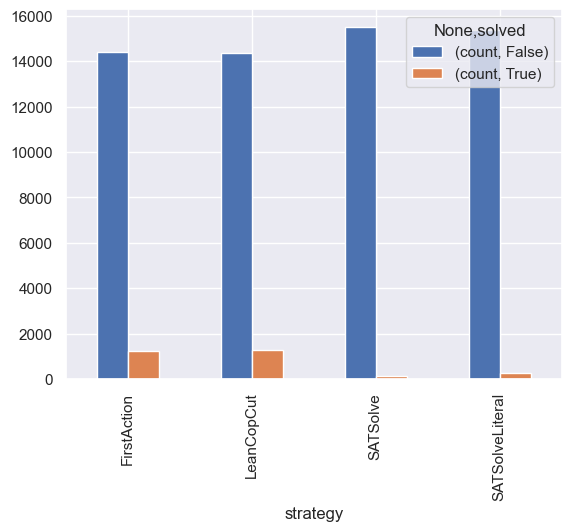

In [19]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='winner', ylabel='loser'>

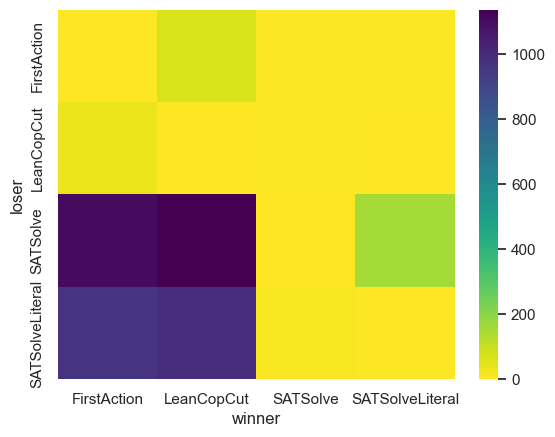

In [20]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [21]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [23]:
merged.xs('SYN344-1.p')

status_left  solved_left  steps_left  \
strategy_left   strategy_right                                         
FirstAction     FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
LeanCopCut      FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
SATSolve        FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   
SATSolveLiteral FirstAction         timeout        False         NaN   
                LeanCopCut          timeout        False         NaN   
                SATSolve            timeout        False         NaN   
                SATSolveLiteral     timeout        False         NaN   

                                 time_ms_left info_left error_left  \
strategy_left   strategy_right                                       
FirstAction     FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
LeanCopCut      FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
SATSolve        FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   
SATSolveLiteral FirstAction               NaN       NaN        NaN   
                LeanCopCut                NaN       NaN        NaN   
                SATSolve                  NaN       NaN        NaN   
                SATSolveLiteral           NaN       NaN        NaN   

                                status_right  solved_right  steps_right  \
strategy_left   strategy_right                                            
FirstAction     FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral      timeout         False          NaN   
LeanCopCut      FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral      timeout         False          NaN   
SATSolve        FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral      timeout         False          NaN   
SATSolveLiteral FirstAction          timeout         False          NaN   
                LeanCopCut           timeout         False          NaN   
                SATSolve             timeout         False          NaN   
                SATSolveLiteral      timeout         False          NaN   

                                 time_ms_right info_right error_right  
strategy_left   strategy_right                     

In [31]:
statistics = (
    merged
    .xs('SATSolveLiteral', level = 'strategy_right')
    .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    .loc[lambda x: x.index.get_level_values('strategy_left') != 'SATSolve']
    # .groupby(level = 'problem')
    # .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics

status_left  solved_left  steps_left  time_ms_left  \
problem    strategy_left                                                      
GRP007-1.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   
GRP018-1.p FirstAction       timeout        False         NaN           NaN   
GRP019-1.p FirstAction       timeout        False         NaN           NaN   
GRP020-1.p FirstAction       timeout        False         NaN           NaN   
GRP021-1.p FirstAction       timeout        False         NaN           NaN   
LCL843-1.p FirstAction       timeout        False         NaN           NaN   
           LeanCopCut        timeout        False         NaN           NaN   

                         info_left error_left status_right  solved_right  \
problem    strategy_left                                                   
GRP007-1.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   
GRP018-1.p FirstAction         NaN        NaN       solved          True   
GRP019-1.p FirstAction         NaN        NaN       solved          True   
GRP020-1.p FirstAction         NaN        NaN       solved          True   
GRP021-1.p FirstAction         NaN        NaN       solved          True   
LCL843-1.p FirstAction         NaN        NaN       solved          True   
           LeanCopCut          NaN        NaN       solved          True   

                          steps_right  time_ms_right info_right error_right  \
problem    strategy_left                                                      
GRP007-1.p FirstAction           69.0           22.0    Theorem         NaN   
           LeanCopCut            69.0           22.0    Theorem         NaN   
GRP018-1.p FirstAction           98.0           41.0    Theorem         NaN   
GRP019-1.p FirstAction           98.0           39.0    Theorem         NaN   
GRP020-1.p FirstAction           98.0           35.0    Theorem         NaN   
GRP021-1.p FirstAction           98.0           40.0    Theorem         NaN   
LCL843-1.p FirstAction          121.0          981.0    Theorem         NaN   
           LeanCopCut           121.0          981.0    Theorem         NaN   

                          length  
problem    strategy_left          
GRP007-1.p FirstAction         7  
           LeanCopCut          7  
GRP018-1.p FirstAction         3  
GRP019-1.p FirstAction         3  
GRP020-1.p FirstAction         3  
GRP021-1.p FirstAction         3  
LCL843-1.p FirstAction       207  
           LeanCopCut        207

# 

In [ ]:
pandas.Series(tr)